Wrapper methods

In [1]:
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

data = load_breast_cancer()
x = data.data
y = data.target


In [2]:
print(x.shape)

(569, 30)


In [3]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter = 5000))
])

selector = SequentialFeatureSelector(
    model,
    n_features_to_select = 5,
    direction = "forward",  #forward feature selection
    scoring = "accuracy",
    cv = 5
)

selector.fit(x, y)

print(data.feature_names[selector.get_support()])

['mean symmetry' 'concavity error' 'worst texture' 'worst perimeter'
 'worst smoothness']


Backward feature elimination

In [4]:
selector = SequentialFeatureSelector(
    model,
    n_features_to_select = 5,
    direction = "backward",  #backward feature elimination
    scoring = "accuracy",
    cv = 5
)

selector.fit(x, y)

print(data.feature_names[selector.get_support()])

['mean texture' 'mean concave points' 'worst area' 'worst smoothness'
 'worst concavity']


Recursive Feature Elimination

In [5]:
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

data = load_breast_cancer()
x = data.data
y = data.target

x_scaled = StandardScaler().fit_transform(x)

model = LogisticRegression(max_iter = 5000)

selector = RFE(
    estimator = model,
    n_features_to_select = 5,
    step = 1  #remove one feature in each iteration.
)

selector.fit(x_scaled, y)

for name, selected, rank in zip(
    data.feature_names, 
    selector.support_,  #Boolean array showing each selected feature.
    selector.ranking_   # RFE rank of every feature.
):
    
    print(name, selected, rank)

mean radius False 12
mean texture False 14
mean perimeter False 15
mean area False 8
mean smoothness False 23
mean compactness False 10
mean concavity False 13
mean concave points False 3
mean symmetry False 25
mean fractal dimension False 20
radius error True 1
texture error False 22
perimeter error False 9
area error False 4
smoothness error False 18
compactness error False 6
concavity error False 24
concave points error False 21
symmetry error False 17
fractal dimension error False 16
worst radius True 1
worst texture True 1
worst perimeter False 2
worst area True 1
worst smoothness False 7
worst compactness False 26
worst concavity False 5
worst concave points True 1
worst symmetry False 11
worst fractal dimension False 19


RFECV  - RFE with Cross Validation

In [6]:
from sklearn.feature_selection import RFECV
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

model = LogisticRegression(max_iter = 5000)

cv = StratifiedKFold(
    n_splits = 5, #5 - Fold
    shuffle = True,
    random_state = 42
)

selector = RFECV(
    estimator = model,
    step = 1,
    cv = cv,
    scoring = "accuracy",
    min_features_to_select = 1
)

selector.fit(x_scaled, y)

print("Optimal number of features : \n", data.feature_names[selector.support_])

Optimal number of features : 
 ['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean compactness' 'mean concavity' 'mean concave points' 'radius error'
 'perimeter error' 'area error' 'smoothness error' 'compactness error'
 'symmetry error' 'fractal dimension error' 'worst radius' 'worst texture'
 'worst perimeter' 'worst area' 'worst smoothness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


Embedded Methods

In [7]:
import numpy as np
import pandas as pd 
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LassoCV
from sklearn.preprocessing import StandardScaler

data = load_diabetes()
x = pd.DataFrame(data.data, columns = data.feature_names)
y = data.target

scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

lasso = LassoCV(
    cv = 5,
    random_state = 42,
    max_iter = 10000
)

lasso.fit(x_scaled, y)

coefficients = pd.Series(
    lasso.coef_,
    index = x.columns
)

selected_features = coefficients[
    coefficients.abs() > 1e-6
]

print("Best alpha : ", lasso.alpha_)
print("Selected features : ")
print(selected_features)

Best alpha :  0.07891843500595848
Selected features : 
age    -0.308921
sex   -11.225046
bmi    24.816849
bp     15.271304
s1    -27.085410
s2     14.386231
s4      6.835041
s5     31.864972
s6      3.179041
dtype: float64


L1-regularized Logistic Regression

In [8]:
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import SelectFromModel 
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

data = load_breast_cancer()
x = data.data
y = data.target

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("selection", SelectFromModel(
        LogisticRegression(     #Here Logistic regression for feature selection
            penalty = "l1",
            solver = "liblinear",
            C = 0.1,  
            max_iter = 5000
        ))), ("classification", LogisticRegression(max_iter = 5000))])

pipeline.fit(x, y)

mask = pipeline.named_steps["selection"].get_support()

print(data.feature_names[mask])

['mean concave points' 'radius error' 'worst radius' 'worst texture'
 'worst smoothness' 'worst concavity' 'worst concave points'
 'worst symmetry']


c:\Users\bda\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\bda\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


Decision-tree feature importance

How Random Forest Classifier can be used for Feature Selection

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_iris
from sklearn.feature_selection import SelectFromModel

iris = load_iris()
x, y = iris.data, iris.target
x.shape

(150, 4)

In [10]:
clf = RandomForestClassifier(n_estimators = 10)
clf = clf.fit(x, y)
clf.feature_importances_

array([0.10424659, 0.0147764 , 0.54270792, 0.3382691 ])

Assignment From above select two features and that 2 features should be displayed

In [11]:
model = SelectFromModel(clf, prefit = True)
x_new = model.transform(x)
x_new.shape

(150, 2)

In [12]:
x_new

array([[1.4, 0.2],
       [1.4, 0.2],
       [1.3, 0.2],
       [1.5, 0.2],
       [1.4, 0.2],
       [1.7, 0.4],
       [1.4, 0.3],
       [1.5, 0.2],
       [1.4, 0.2],
       [1.5, 0.1],
       [1.5, 0.2],
       [1.6, 0.2],
       [1.4, 0.1],
       [1.1, 0.1],
       [1.2, 0.2],
       [1.5, 0.4],
       [1.3, 0.4],
       [1.4, 0.3],
       [1.7, 0.3],
       [1.5, 0.3],
       [1.7, 0.2],
       [1.5, 0.4],
       [1. , 0.2],
       [1.7, 0.5],
       [1.9, 0.2],
       [1.6, 0.2],
       [1.6, 0.4],
       [1.5, 0.2],
       [1.4, 0.2],
       [1.6, 0.2],
       [1.6, 0.2],
       [1.5, 0.4],
       [1.5, 0.1],
       [1.4, 0.2],
       [1.5, 0.2],
       [1.2, 0.2],
       [1.3, 0.2],
       [1.4, 0.1],
       [1.3, 0.2],
       [1.5, 0.2],
       [1.3, 0.3],
       [1.3, 0.3],
       [1.3, 0.2],
       [1.6, 0.6],
       [1.9, 0.4],
       [1.4, 0.3],
       [1.6, 0.2],
       [1.4, 0.2],
       [1.5, 0.2],
       [1.4, 0.2],
       [4.7, 1.4],
       [4.5, 1.5],
       [4.9,

Feature Selection using Pipeline

In [13]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

clfs = Pipeline([('feature_selection', SelectFromModel(RandomForestClassifier(n_estimators = 10))),('classification', KNeighborsClassifier())])

model = clfs.fit(x, y)
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_selection', ...), ('classification', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](3,)","[0,1,2]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,4
,"estimator estimator: objectThe base estimator from which the transformer is built.This can be both a fitted (if ``prefit`` is set to True)or a non-fitted estimator. The estimator should have a``feature_importances_`` or ``coef_`` attribute after fitting.Otherwise, the ``importance_getter`` parameter should be used.",RandomForestC...estimators=10)
,"threshold threshold: str or float, default=NoneThe threshold value to use for feature selection. Features whoseabsolute importance value is greater or equal are kept while the othersare discarded. If ""median"" (resp. ""mean""), then the ``threshold`` valueis the median (resp. the mean) of the feature importances. A scalingfactor (e.g., ""1.25*mean"") may also be used. If None and if theestimator has a parameter penalty set to l1, either explicitlyor implicitly (e.g, Lasso), the threshold used is 1e-5.Otherwise, ""mean"" is used by default.",None
,"prefit prefit: bool, default=FalseWhether a prefit model is expected to be passed into the constructordirectly or not.If `True`, `estimator` must be a fitted estimator.If `False`, `estimator` is fitted and updated by calling`fit` and `partial_fit`, respectively.",False
,"norm_order norm_order: non-zero int, inf, -inf, default=1Order of the norm used to filter the vectors of coefficients below``threshold`` in the case where the ``coef_`` attribute of theestimator is of dimension 2.",1


Logistic Regression

In [ ]:
import pandas as pd

data = {
    "Study_hours" : [1, 2, 2, 3, 4, 5, 6, 7, 8, 9],
    "Attendance"  : [50, 55, 60, 6, 70, 75, 75, 80, 90, 95],
    "Pass"        : [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
}

df = pd.DataFrame(data)

x = df[["Study_hours", "Attendance"]]
y = df["Pass"]

Split the Dataset

In [16]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size =0.3,
    random_state = 42,
    stratify = y
)

Scale the Features

In [17]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

The scaler is fitted only on the training data to avoid data leakage.

Train the Model

In [19]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()

model.fit(x_train_scaled, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default sol

Make Predictions

In [20]:
y_pred = model.predict(x_test_scaled)
y_probability = model.predict_proba(x_test_scaled)

print("Predicted classes : ", y_pred)
print("Class probabilities : \n", y_probability)

Predicted classes :  [0 0 1]
Class probabilities : 
 [[0.94123215 0.05876785]
 [0.99373541 0.00626459]
 [0.02194839 0.97805161]]


In [22]:
print("Intercept : ", model.intercept_)
print("Coefficients : ", model.coef_)

Intercept :  [0.42610721]
Coefficients :  [[0.91130326 0.78163544]]


You have y-pred and y_test. find the Confusion Matrix, Prediction Accuracy, Prediction Classification Report, 

ROC Curve and AUC

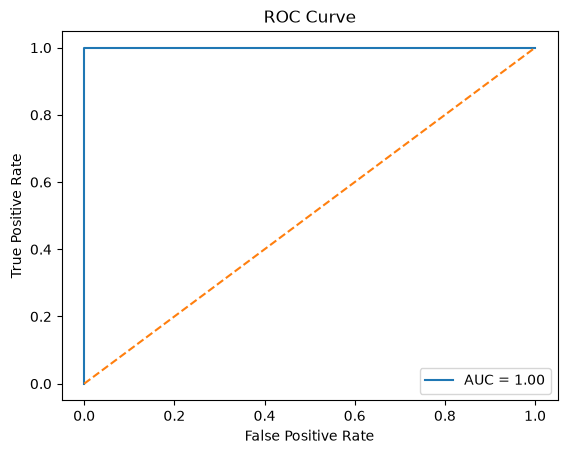

In [24]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt 

prob_positive = model.predict_proba(x_test_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, prob_positive)
auc_value = roc_auc_score(y_test, prob_positive)

plt.plot(fpr, tpr, label = f"AUC = {auc_value:.2f}")
plt.plot([0, 1], [0, 1], linestyle = "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

Assignment 3 :Change datasets, other dataset, apply Logisitic Regression adn plot ROC curve